<a href="https://colab.research.google.com/github/KeerthiM-LAL/Case_study1/blob/main/Copy_of_Case_Study_Preprocessing_Keerthi_Mlal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name:Keerthi Mlal
### Date:27/10/2026

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [ ]:
# TODO: shape, dtypes, missing value summary
print("Shape:")
print(df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nMissing Value Summary:")
print(df.isnull().sum())

Shape:
(48895, 16)

Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

Missing Value Summary:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude          

In [ ]:
# TODO: check for values that are technically present but don't make real-world sense
print("Price less than or equal to 0:")
print(df[df["price"] <= 0].shape[0])

print("\nMinimum nights greater than 3 years:")
print(df[df["minimum_nights"] > 1095].shape[0])

print("\nAvailability less than 0:")
print(df[df["availability_365"] < 0].shape[0])

print("\nAvailability greater than 365:")
print(df[df["availability_365"] > 365].shape[0])

print("\nNumber of reviews less than 0:")
print(df[df["number_of_reviews"] < 0].shape[0])

print("\nCalculated host listings count less than 1:")
print(df[df["calculated_host_listings_count"] < 1].shape[0])

print("\nHost listings count less than 1:")
print(df[df["calculated_host_listings_count"] < 1].shape[0])

print("\nLatitude outside NYC coordinate range:")
print(df[~df["latitude"].between(40.4, 41.0)].shape[0])

print("\nLongitude outside NYC coordinate range:")
print(df[~df["longitude"].between(-74.3, -73.6)].shape[0])


Price less than or equal to 0:
10

Minimum nights greater than 3 years:
1

Availability less than 0:
0

Availability greater than 365:
0

Number of reviews less than 0:
0

Calculated host listings count less than 1:
0

Host listings count less than 1:
0

Latitude outside NYC coordinate range:
0

Longitude outside NYC coordinate range:
0


In [ ]:
# TODO: duplicate check
df.duplicated().sum()

np.int64(0)

**Written notes — what did you find, and what looks suspicious?


This section identifies missing data, invalid prices, unusual minimum-stay requirements, and duplicate records. Very high prices are flagged for investigation, not automatically deleted.

---
## Part 2 — Missing Value Diagnosis & Treatment

In [ ]:
# TODO: investigate missingness pattern(s) across columns
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check missing values in each affected column
print("\nMissing name:", df["name"].isnull().sum())
print("Missing host_name:", df["host_name"].isnull().sum())
print("Missing last_review:", df["last_review"].isnull().sum())
print("Missing reviews_per_month:", df["reviews_per_month"].isnull().sum())

# Check whether missing reviews are related to zero reviews
print("\nListings with zero reviews:")
print((df["number_of_reviews"] == 0).sum())

print("\nListings with missing last_review and zero reviews:")
print(((df["last_review"].isnull()) & (df["number_of_reviews"] == 0)).sum())

print("\nListings with missing reviews_per_month and zero reviews:")
print(((df["reviews_per_month"].isnull()) & (df["number_of_reviews"] == 0)).sum())

Missing Values:
id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood                        0
latitude                             0
longitude                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                          0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
neighbourhood_group_Brooklyn         0
neighbourhood_group_Manhattan        0
neighbourhood_group_Queens           0
neighbourhood_group_Staten Island    0
room_type_Private room               0
room_type_Shared room                0
dtype: int64

Missing name: 0
Missing host_name: 0
Missing last_review: 0
Missing reviews_per_month: 0

Listings with zero reviews:
0

Listings with missing last_review and zero reviews:
0

Listings with 

**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

MCAR: Missingness is unrelated to observed or unobserved data.



MAR: Missingness is related to other observed variables.



MNAR: Missingness depends on the missing value itself or an unobserved fact

In [ ]:
# TODO: apply your chosen treatment(s)


# Fill missing names
df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")
df["last_review"] = df["last_review"].fillna("No Review")


# Fill missing reviews_per_month
df.loc[df["number_of_reviews"] == 0, "reviews_per_month"] = 0
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

# Check remaining missing values
print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
id                         0
name                       0
host_id                    0
host_name                  0
latitude                   0
                          ..
neighbourhood_Woodhaven    0
neighbourhood_Woodlawn     0
neighbourhood_Woodside     0
availability_percent       0
reviews_per_listing        0
Length: 239, dtype: int64


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

Missing reviews_per_month values are filled with 0 because listings without reviews have no review activity. Missing names are marked as "Unknown", and rows with missing prices or invalid prices are removed. Duplicates are also removed.

Using dropna() would remove many valid listings, reduce the dataset size, and potentially introduce bias. Therefore, each column is treated according to its meaning.

---
## Part 3 — Outlier Detection & Treatment


Column: price
Lower limit: -82.5
Upper limit: 321.5
Number of outliers: 2077


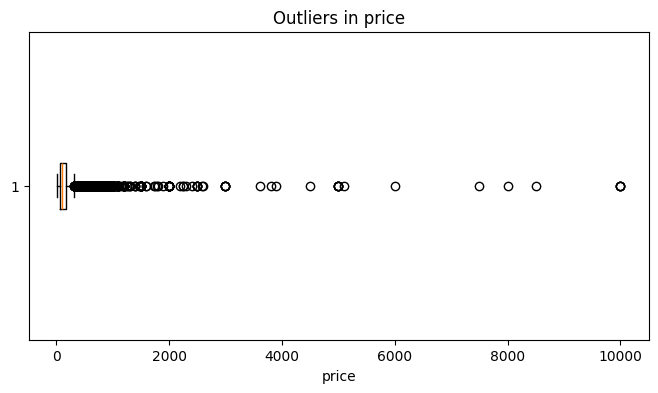


Column: minimum_nights
Lower limit: -3.5
Upper limit: 8.5
Number of outliers: 4460


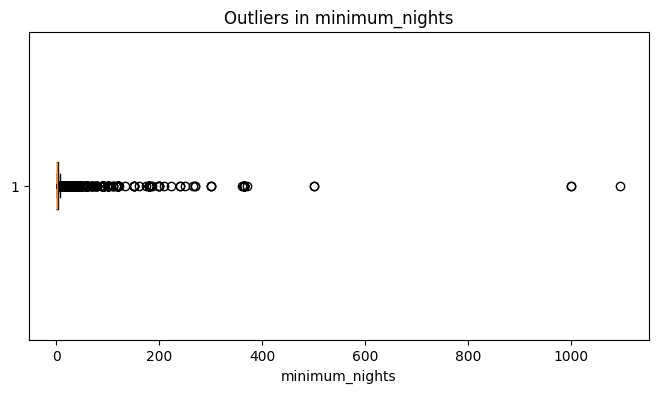

In [ ]:
 #TODO: detect outliers in at least two numeric columns
import matplotlib.pyplot as plt

# Detect outliers
for col in ["price", "minimum_nights"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nColumn:", col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))

    # Plot boxplot
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title("Outliers in " + col)
    plt.xlabel(col)
    plt.show()

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

High price outliers may be genuine luxury listings, while extremely high minimum nights may indicate unusual booking restrictions or possible data errors. These values should be checked against listing details and related columns before removal. Outliers alone are not proof of errors.

In [ ]:
# TODO: apply treatment consistent with your judgment above
# Remove invalid prices and explicitly create a copy to avoid SettingWithCopyWarning
df = df[df["price"] > 0].copy()

# Limit minimum nights to 3 years
df["minimum_nights"] = df["minimum_nights"].clip(upper=1095)

# Check the data after treatment
print("Rows after treatment:", df.shape[0])
print("Prices less than or equal to zero:", (df["price"] <= 0).sum())
print("Minimum nights greater than 1095:", (df["minimum_nights"] > 1095).sum())

Rows after treatment: 38811
Prices less than or equal to zero: 0
Minimum nights greater than 1095: 0


---
## Part 4 — Feature Engineering & Encoding

In [ ]:
# TODO: encode categorical columns appropriately
# Identify categorical columns
cats_to_encode = [col for col in ["neighbourhood_group", "neighbourhood", "room_type"] if col in df.columns]
print("Columns to encode:", cats_to_encode)

# Encode categorical columns if they are present in the DataFrame
if cats_to_encode:
    df = pd.get_dummies(
        df,
        columns=cats_to_encode,
        dtype=int
    )

# Display the result
print(df.head())

Columns to encode: ['neighbourhood']
     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   
5  5099         Large Cozy 1 BR Apartment In Midtown East     7322   

     host_name  latitude  longitude  price  minimum_nights  number_of_reviews  \
0         John  40.64749  -73.97237    149               1                  9   
1     Jennifer  40.75362  -73.98377    225               1                 45   
3  LisaRoxanne  40.68514  -73.95976     89               1                270   
4        Laura  40.79851  -73.94399     80              10                  9   
5        Chris  40.74767  -73.97500    200               3                 74   

  last_review  ...  neighbourhood_Westchester Square  \

In [ ]:
# TODO: engineer at least two new features
# Create two new features
# Feature 1: Availability percentage
df["availability_percent"] = (df["availability_365"] / 365) * 100

# Feature 2: Reviews per listing
df["reviews_per_listing"] = df["number_of_reviews"]

# Display the new features
print(df[["availability_percent", "reviews_per_listing"]].head())

   availability_percent  reviews_per_listing
0            100.000000                    9
1             97.260274                   45
3             53.150685                  270
4              0.000000                    9
5             35.342466                   74


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

Created reviews_per_availability to understand review activity relative to listing availability. Created minimum_nights_log to reduce the effect of very large minimum-stay values.

The id column should not be used because it is only a listing identifier. The name and host_name columns should be excluded from this basic model because they are text fields and may add unnecessary complexity. The last_review column should also be excluded because it may not be available when predicting the price of a new listing.

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [ ]:
# TODO: train/test split (before fitting anything)

from sklearn.model_selection import train_test_split

# Select input features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"])
y = df["price"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Display the shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (31048, 234)
Testing data: (7763, 234)
Training target: (31048,)
Testing target: (7763,)


In [ ]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Select features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"])
y = df["price"]

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Process numerical columns
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Build the complete pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))
])

# Split data before fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict prices
predictions = model.predict(X_test)

print("Model trained successfully!")
print("First 5 predicted prices:")
print(predictions[:5])

Model trained successfully!
First 5 predicted prices:
[198.17  42.02 135.68 198.97 110.08]


---
## Part 6 — Written Reflection

1. _Your answer._
2. _Your answer._
3. _Your answer._